# 01 · Análisis exploratorio, auditoría y preparación de datos

**Proyecto:** AGRAR Berry Good Idea (Sabana Hack 2026) · **Módulo:** `vision/` · **Robot objetivo:** AgiBot X2 Ultra (RGB-D Orbbec Gemini 335, inferencia en PC2).

Este notebook es el centro de comprensión de los datos: inventario, inspección visual, auditoría de calidad, análisis de anotaciones, armonización de clases, particiones sin fugas y exportación del manifiesto. **No entrena modelos** (eso está en `02_model_training_and_evaluation.ipynb`).

Reglas que sigue:
- Rutas relativas a `vision/` (se detecta automáticamente); ningún dato se modifica.
- Las imágenes de datasets de terceros se guardan como paneles en `reports/figures_local/` (ignorado por Git) y **no** se incrustan en las salidas guardadas (`SHOW_PANELS = False`).
- Se distingue: hecho verificado, observación automática, error confirmado manualmente e hipótesis.

## 1. Contexto, objetivos y fuentes

**Problema empresarial.** AGRAR quiere que un robot recorra camas de arándano y emita alertas *informativas* sobre posibles problemas fitosanitarios (Botrytis, Alternaria, trips), priorizando **no omitir casos** (falsos negativos) sin saturar de falsas alarmas. El sistema solo informa; no actúa sobre el cultivo.

**Objetivo de este análisis.** Decidir con evidencia qué datos pueden entrenar un primer modelo, cuáles son solo auxiliares y qué falta.

**Estado de adquisición** (detalle en `reports/dataset_selection_report.md`):

In [1]:
import sys, json, collections, warnings
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

from importlib import import_module
def _root():
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "pyproject.toml").exists() and (c / "src" / "berryvision").is_dir():
            return c
    raise FileNotFoundError("Ejecute el notebook desde vision/ o una subcarpeta")
VISION = _root(); sys.path.insert(0, str(VISION / "src"))
from berryvision.manifest import read_manifest_csv
from berryvision.nbutils import image_stats, save_panel, boxes_of

SHOW_PANELS = False          # True solo en revisión local: incrusta imágenes de terceros en el notebook
FIG = VISION / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
PANELS = VISION / "reports" / "figures_local"; PANELS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110, "figure.figsize": (9, 3.6)})

catalog = yaml.safe_load((VISION / "knowledge/datasets/catalog.yaml").read_text(encoding="utf-8"))
pd.DataFrame([{"id": d["id"], "papel": d.get("role"), "estado": d.get("status"),
               "licencia": str(d.get("license"))[:60]} for d in catalog["datasets"]])

,id,papel,estado,licencia
0,drberry_original_v1,Núcleo inicial,PARCIALMENTE_VERIFICADO,CC BY 4.0 (Roboflow) + citar el artículo [H]
1,drberry_gen3_20_v1,Núcleo inicial (alternativo),PARCIALMENTE_VERIFICADO,CC BY 4.0
2,drberry_gen3_v1,Auxiliar,PARCIALMENTE_VERIFICADO,CC BY 4.0
3,afzaal_strawberry,Investigación complementaria,PARCIALMENTE_VERIFICADO,CC BY 4.0 [H]
4,plantdoc_blueberry,Auxiliar,VERIFICADO,CC BY 4.0 declarada [H]; derechos de las fotos originales in
5,plantvillage_blueberry_healthy,Auxiliar (control de sesgo de dominio),VERIFICADO,CC BY-SA 3.0 según la ficha de Hugging Face mohanty/PlantVil
6,strawberry_hybrid,Investigación complementaria,PARCIALMENTE_VERIFICADO,CC BY-NC 4.0
7,thrip_leaf,Bloqueado,BLOQUEADO_POR_LICENCIA,README: solo investigación académica no comercial; prohíbe r
8,hyperspectral_blueberries,Fuera de alcance inicial,VERIFICADO (metadatos),CC BY 4.0 (datos); código en GitHub sin licencia


In [2]:
acq = {}
for p in sorted((VISION / "data/external").glob("*/ACQUISITION.json")):
    a = json.loads(p.read_text(encoding="utf-8"))
    acq[p.parent.name] = {"origen": a.get("source_repo") or a.get("url"), "version": a.get("commit") or a.get("archive_sha256", "")[:16],
                          "licencia": a.get("license"), "adquirido": a.get("acquired_at")}
pending = {"drberry (núcleo)": "BLOQUEADO: ROBOFLOW_API_KEY no definida", "afzaal (original)": "Dropbox deshabilitado; sus bases están dentro de strawberry_hybrid",
           "thrip_leaf": "BLOQUEADO por licencia/acceso", "hyperspectral": "fuera de alcance (otra modalidad)"}
display(pd.DataFrame(acq).T)
pd.Series(pending, name="pendientes")

,origen,version,licencia,adquirido
plantdoc_blueberry,https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset,4730a233a555b30ee98e0879c63ad25d82407455,CC BY 4.0 (LICENSE.txt del repositorio); imágenes recopiladas de internet,2026-10-23T23:21:28+00:00
plantvillage_blueberry_healthy,https://github.com/spMohanty/PlantVillage-Dataset,7f7ecc7e1eaca78107e3affe7cb5abd9427e139a,CC BY-SA 3.0 (ficha de Hugging Face mohanty/PlantVillage; sin LICENSE en Git...,2026-10-23T23:18:30+00:00
strawberry_hybrid,https://data.mendeley.com/public-api/zip/k2ptxmfjhj/download/1,cc1311b952cae85d,CC BY-NC 4.0 (no comercial). Bases de Afzaal 2021 y Pérez-Borrero 2020,2026-10-24T00:22:32+00:00


drberry (núcleo)                                BLOQUEADO: ROBOFLOW_API_KEY no definida
afzaal (original)    Dropbox deshabilitado; sus bases están dentro de strawberry_hybrid
thrip_leaf                                                BLOQUEADO por licencia/acceso
hyperspectral                                         fuera de alcance (otra modalidad)
Name: pendientes, dtype: str

**Alcance de cada tarea visual con los datos disponibles hoy:**

| Fuente local | Cultivo | Qué permite | Qué NO permite |
|---|---|---|---|
| `plantvillage_blueberry_healthy` | arándano | control de sesgo de dominio (hojas de laboratorio) | entrenar enfermedades de arándano |
| `plantdoc_blueberry` | arándano | detectar *hojas* en escenas variadas (tras revisión) | "sana" vs enfermedad (la etiqueta no es diagnóstico) |
| `strawberry_traditional` | fresa | experimento auxiliar de clasificación de enfermedades (incluye `gray_mold`) | afirmar nada sobre Botrytis en arándano |
| `strawberry_hybrid_synthetic` | fresa (sintética) | solo metadatos | entrenar/evaluar (excluida por política) |

**DrBerry (Alternaria/Oidio/Heliothis en arándano) sigue sin descargar**: todos los análisis que dependen de él quedan pendientes y se señalan donde corresponde.

## 2. Inventario de archivos (imágenes vs. instancias)

In [3]:
M = read_manifest_csv(VISION / "data/processed/manifest_v1.csv")
df = pd.DataFrame(M)
meta = json.loads((VISION / "manifests/manifest_v1.meta.json").read_text(encoding="utf-8"))
print("manifiesto v", meta["manifest_version"], "sha256", meta["manifest_sha256"][:16], "| filas", len(df))
inv = df.groupby("source_id").agg(
    imagenes=("image_id", "count"), instancias=("n_instances", "sum"),
    clases_originales=("original_label", lambda s: s.nunique()),
    ilegibles_o_sin_hash=("sha256", lambda s: int((s == "").sum() + s.isna().sum())),
    aumentadas=("is_augmented", "sum"), sinteticas=("is_synthetic", "sum"),
    anotacion=("annotation_type", lambda s: ", ".join(sorted(set(s)))))
dup = df[df.sha256.astype(bool)].groupby("sha256").source_id.agg(list)
inv["duplicados_exactos"] = inv.index.map(lambda s: int(sum(len(v) - 1 for v in dup if v.count(s) > 1 and len(set(v)) == 1)))
inv

manifiesto v 1.0.0 sha256 71f6055289b4e2b6 | filas 7228


,imagenes,instancias,clases_originales,ilegibles_o_sin_hash,aumentadas,sinteticas,anotacion,duplicados_exactos
source_id,,,,,,,,
plantdoc_blueberry,117,849,1,0,0,0,boxes_leaf,1
plantvillage_blueberry_healthy,1502,1502,1,0,0,0,image_label,0
strawberry_hybrid_synthetic,1018,0,9,1018,0,1018,polygons_lesion_or_organ,0
strawberry_traditional,4591,8693,10,0,1558,0,polygons_lesion_or_organ,0


In [4]:
res = (df.assign(res=df.width.astype(str) + "x" + df.height.astype(str), aspecto=(df.width / df.height).round(2))
         .groupby("source_id").agg(resoluciones_distintas=("res", "nunique"), resolucion_mas_comun=("res", lambda s: s.mode().iat[0] if len(s.mode()) else None),
                                  aspecto_min=("aspecto", "min"), aspecto_max=("aspecto", "max"), ancho_mediana=("width", "median")))
res

,resoluciones_distintas,resolucion_mas_comun,aspecto_min,aspecto_max,ancho_mediana
source_id,,,,,
plantdoc_blueberry,91,1600x1200,0.56,1.84,1200.0
plantvillage_blueberry_healthy,1,256x256,1.00,1.00,256.0
strawberry_hybrid_synthetic,1,640x640,1.00,1.00,640.0
strawberry_traditional,1,640x640,1.00,1.00,640.0


**Lectura.** Las imágenes de fresa vienen **ya reescaladas a 640×640** por los autores (las bases de Afzaal eran de 419 px: hay sobremuestreo). PlantVillage es 256×256 uniforme. PlantDoc es heterogéneo (91 resoluciones, fotos de internet). Ninguna fuente se parece a la cámara del robot (1280×720, 16:9, MJPEG): la relación de aspecto y la escala de los síntomas cambian.

## 3. Exploración de clases

In [5]:
cls = (df[df.canonical_label != ""].groupby(["source_id", "canonical_label", "is_augmented"]).size()
       .unstack(fill_value=0).rename(columns={False: "originales", True: "aumentadas"}))
cls["total"] = cls.sum(1)
cls

is_augmented                                                         originales  aumentadas  total
source_id                      canonical_label                                                    
plantdoc_blueberry             blueberry_leaf_unspecified_condition         117           0    117
plantvillage_blueberry_healthy blueberry_leaf_healthy_lab                  1502           0   1502
strawberry_traditional         strawberry_asymptomatic                      574           0    574
                               strawberry_flower_blossom_blight             209         366    575
                               strawberry_fruit_anthracnose_rot              97         476    573
                               strawberry_fruit_powdery_mildew              135         438    573
                               strawberry_gray_mold                         476          97    573
                               strawberry_leaf_angular_leafspot             435         139    574
                               strawberry_leaf_powdery_mildew               533          41    574
                               strawberry_leaf_spot                         569           0    569

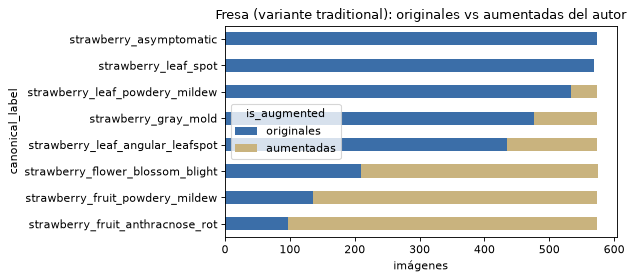

In [6]:
sw = cls.loc["strawberry_traditional"].sort_values("originales")
ax = sw[["originales", "aumentadas"]].plot.barh(stacked=True, figsize=(8, 3.6), color=["#3b6ea8", "#c9b37e"])
ax.set_xlabel("imágenes"); ax.set_title("Fresa (variante traditional): originales vs aumentadas del autor")
plt.tight_layout(); plt.savefig(FIG / "eda_strawberry_class_balance.png"); plt.show()

**Lectura.** El conjunto "equilibrado" (~700 por clase) lo es **solo por las aumentadas del autor**. Entre las imágenes originales hay un desbalance real (p. ej. pocas de *anthracnose* frente a muchas de *leaf spot*). Por eso el notebook 02 compara entrenar con originales solamente (desbalance real, donde la CE ponderada y la Focal tienen sentido) frente a originales + aumentadas.

## 4. Inspección visual (paneles locales)

In [7]:
rng = np.random.default_rng(0)
panels = {}
def pick(rows, n=12):
    idx = rng.choice(len(rows), size=min(n, len(rows)), replace=False)
    return [rows[i] for i in idx]
for lab, g in df[(df.source_id == "strawberry_traditional") & (df.split != "excluded") & (~df.is_augmented)].groupby("canonical_label"):
    items = [{"rel_path": r.rel_path, "title": f"{lab[11:]} {r.split}", "boxes": boxes_of(r._asdict())} for r in pick(list(g.itertuples()), 6)]
    panels[lab] = save_panel(items, VISION, PANELS / f"eda_strawberry_{lab}.jpg")
for src in ("plantvillage_blueberry_healthy", "plantdoc_blueberry"):
    g = list(df[df.source_id == src].itertuples())
    items = [{"rel_path": r.rel_path, "title": f"{src[:14]} {r.split}", "boxes": boxes_of(r._asdict())} for r in pick(g, 12)]
    panels[src] = save_panel(items, VISION, PANELS / f"eda_{src}.jpg")
syn = list(df[df.is_synthetic].itertuples())
panels["sinteticas"] = save_panel([{"rel_path": r.rel_path, "title": "SINTÉTICA " + r.original_label[:20]} for r in pick(syn, 12)],
                                  VISION, PANELS / "eda_synthetic_excluded.jpg", draw_boxes=False)
aug = list(df[(df.source_id == "strawberry_traditional") & df.is_augmented].itertuples())
panels["aumentadas"] = save_panel([{"rel_path": r.rel_path, "title": "aug " + r.canonical_label[11:]} for r in pick(aug, 12)],
                                  VISION, PANELS / "eda_augmented.jpg", draw_boxes=False)
if SHOW_PANELS:
    from IPython.display import Image as _I, display
    for p in panels.values(): display(_I(filename=str(p)))
pd.Series({k: str(v.relative_to(VISION)) for k, v in panels.items()}, name="panel local (no versionado)")

strawberry_asymptomatic                      reports\figures_local\eda_strawberry_strawberry_asymptomatic.jpg
strawberry_flower_blossom_blight    reports\figures_local\eda_strawberry_strawberry_flower_blossom_blight.jpg
strawberry_fruit_anthracnose_rot    reports\figures_local\eda_strawberry_strawberry_fruit_anthracnose_rot.jpg
strawberry_fruit_powdery_mildew      reports\figures_local\eda_strawberry_strawberry_fruit_powdery_mildew.jpg
strawberry_gray_mold                            reports\figures_local\eda_strawberry_strawberry_gray_mold.jpg
strawberry_leaf_angular_leafspot    reports\figures_local\eda_strawberry_strawberry_leaf_angular_leafspot.jpg
strawberry_leaf_powdery_mildew        reports\figures_local\eda_strawberry_strawberry_leaf_powdery_mildew.jpg
strawberry_leaf_spot                            reports\figures_local\eda_strawberry_strawberry_leaf_spot.jpg
plantvillage_blueberry_healthy                   reports\figures_local\eda_plantvillage_blueberry_healthy.jpg
plantdoc_b

**Revisión manual de los paneles (registrada, no automática):**
- *PlantVillage*: hoja aislada sobre fondo gris uniforme de laboratorio → riesgo de atajo por fondo si se mezcla con otras fuentes.
- *PlantDoc*: ramas y hojas en entornos diversos; algunas hojas enrojecidas/decoloradas están etiquetadas igual que el resto ("Blueberry leaf") y hay hojas visibles sin caja (anotación incompleta). Una imagen anuncia "iron-deficient".
- *Fresa*: primeros planos de frutos, flores y hojas con síntomas visibles y polígonos sobre lesiones u órganos; fondos de invernadero; algunas imágenes de internet.
- *Sintéticas DALL·E 3*: visualmente plausibles pero no son capturas reales → excluidas.

> Las imágenes sin caja **no** se consideran sanas: puede ser anotación ausente.

## 5. Resoluciones, canales y diferencias de dominio entre fuentes

In [8]:
rows_stats = []
for src, g in df[(df.split != "excluded") & (~df.is_synthetic)].groupby("source_id"):
    for r in g.sample(min(150, len(g)), random_state=0).itertuples():
        s = image_stats(VISION / r.rel_path); s["source_id"] = src; rows_stats.append(s)
dom = pd.DataFrame(rows_stats)
dom.groupby("source_id")[["brightness", "saturation", "sharpness", "mean_r", "mean_g", "mean_b"]].median().round(1)

,brightness,saturation,sharpness,mean_r,mean_g,mean_b
source_id,,,,,,
plantdoc_blueberry,152.4,99.1,2225.0,129.5,134.8,90.4
plantvillage_blueberry_healthy,151.8,50.9,5664.8,143.8,143.3,138.5
strawberry_traditional,128.1,110.2,1176.4,104.8,118.9,74.8


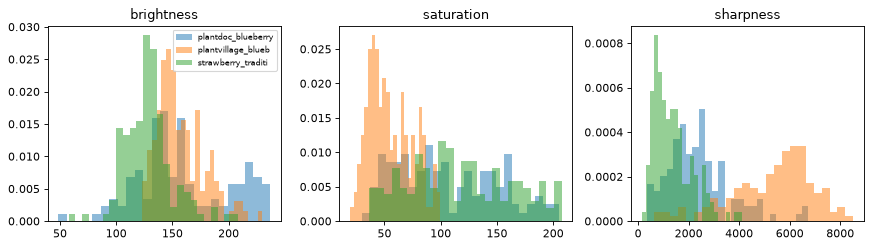

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axs, ["brightness", "saturation", "sharpness"]):
    for src, g in dom.groupby("source_id"):
        ax.hist(g[col], bins=25, alpha=0.5, label=src[:18], density=True)
    ax.set_title(col)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "eda_domain_stats.png"); plt.show()

**Lectura.** Las distribuciones de brillo, saturación y nitidez difieren entre fuentes. Un modelo entrenado con varias fuentes podría separar clases por la **fuente** (fondo, cámara, compresión) en vez de por el síntoma. Por eso el primer modelo usa **una sola fuente por tarea** y la identidad de la fuente se conserva en el manifiesto.

### 5.1 Confusión entre clase y fuente en el dataset de fresa (hallazgo crítico)

Si una clase procede de una fuente distinta a las demás, el modelo puede aprender la **fuente** (fondo, cámara, escala) en lugar del **síntoma**. Se comprueba por el patrón de nombres de archivo: las imágenes de Pérez-Borrero (2020) tienen nombres numéricos; las de Afzaal (2021), el nombre de la enfermedad.

In [10]:
import re
orig = df[(df.source_id == "strawberry_traditional") & (~df.is_augmented) & (df.canonical_label != "")].copy()
orig["origen_probable"] = np.where(orig.base_id.str.fullmatch(r"\d+"), "numérico (Pérez-Borrero 2020)", "por clase (Afzaal 2021)")
ct = pd.crosstab(orig.canonical_label, orig.origen_probable)
assert ct.loc["strawberry_asymptomatic", "numérico (Pérez-Borrero 2020)"] == ct.loc["strawberry_asymptomatic"].sum()
ct

origen_probable,numérico (Pérez-Borrero 2020),por clase (Afzaal 2021)
canonical_label,,
strawberry_asymptomatic,574,0
strawberry_flower_blossom_blight,0,209
strawberry_fruit_anthracnose_rot,0,97
strawberry_fruit_powdery_mildew,0,135
strawberry_gray_mold,0,476
strawberry_leaf_angular_leafspot,0,435
strawberry_leaf_powdery_mildew,0,533
strawberry_leaf_spot,0,569


**Resultado:** el 100 % de `strawberry_asymptomatic` viene de una fuente y el 100 % de las enfermedades de otra. Consecuencias:

1. La **alerta binaria "enfermedad vs. sin síntomas" en fresa NO mide reconocimiento de síntomas**: es separable por la fuente. Sus métricas se reportan solo como diagnóstico del sesgo.
2. Las **confusiones entre las 7 enfermedades** (todas de Afzaal) sí son informativas: el análisis principal de falsos negativos se hace entre enfermedades.
3. Para arándano, la clase sin síntomas **debe** venir de la misma cámara, finca y sesión que las enfermas (DrBerry "Sana" o capturas del robot), nunca de otra fuente.

## 6. ¿Qué describen realmente las etiquetas?

In [11]:
pd.DataFrame([
 {"fuente": "plantvillage_blueberry_healthy", "tipo": "etiqueta de imagen completa", "describe": "hoja sana de laboratorio", "diagnóstico experto": "no documentado"},
 {"fuente": "plantdoc_blueberry", "tipo": "cajas de HOJAS", "describe": "hoja de arándano, condición no especificada", "diagnóstico experto": "no"},
 {"fuente": "strawberry_traditional", "tipo": "polígonos de lesión/órgano (Afzaal) + fruto (Pérez-Borrero)", "describe": "enfermedad visible por instancia", "diagnóstico experto": "verificado por expertos según Afzaal 2021"},
 {"fuente": "drberry (pendiente)", "tipo": "cajas", "describe": "hipótesis: hoja completa con su condición (1 muestra)", "diagnóstico experto": "no publicado"},
 {"fuente": "cualquiera", "tipo": "etiquetas ambientales / severidad", "describe": "no disponibles en las fuentes locales", "diagnóstico experto": "-"}])

,fuente,tipo,describe,diagnóstico experto
0,plantvillage_blueberry_healthy,etiqueta de imagen completa,hoja sana de laboratorio,no documentado
1,plantdoc_blueberry,cajas de HOJAS,"hoja de arándano, condición no especificada",no
2,strawberry_traditional,polígonos de lesión/órgano (Afzaal) + fruto (Pérez-Borrero),enfermedad visible por instancia,verificado por expertos según Afzaal 2021
3,drberry (pendiente),cajas,hipótesis: hoja completa con su condición (1 muestra),no publicado
4,cualquiera,etiquetas ambientales / severidad,no disponibles en las fuentes locales,-


## 7. Tamaño relativo de cajas y máscaras

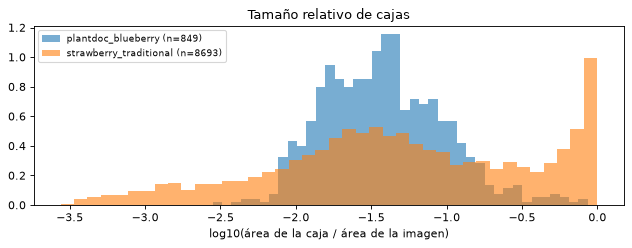

,plantdoc_blueberry,strawberry_traditional
count,849.0000,8693.0000
mean,0.0619,0.2048
std,0.0869,0.2987
min,0.0028,0.0003
10%,0.0127,0.0034
50%,0.0368,0.0472
90%,0.1255,0.7692
max,0.8645,0.9968


In [12]:
def areas(src):
    out = []
    for r in df[df.source_id == src].itertuples():
        for x1, y1, x2, y2 in boxes_of(r._asdict()):
            out.append({"area": max(0, x2 - x1) * max(0, y2 - y1), "rel_path": r.rel_path, "label": r.canonical_label})
    return pd.DataFrame(out)
A = {s: areas(s) for s in ("plantdoc_blueberry", "strawberry_traditional")}
fig, ax = plt.subplots(figsize=(8, 3.2))
for s, a in A.items():
    ax.hist(np.log10(a.area.clip(1e-5)), bins=40, alpha=0.6, label=f"{s} (n={len(a)})", density=True)
ax.set_xlabel("log10(área de la caja / área de la imagen)"); ax.legend(fontsize=8); ax.set_title("Tamaño relativo de cajas")
plt.tight_layout(); plt.savefig(FIG / "eda_box_area.png"); plt.show()
pd.DataFrame({s: a.area.describe(percentiles=[.1, .5, .9]) for s, a in A.items()}).round(4)

In [13]:
sw_a = A["strawberry_traditional"].sort_values("area")
small = [{"rel_path": r.rel_path, "title": f"{r.area:.4f}", "boxes": [b for b in boxes_of(df[df.rel_path == r.rel_path].iloc[0].to_dict())]} for r in sw_a.head(12).itertuples()]
large = [{"rel_path": r.rel_path, "title": f"{r.area:.3f}", "boxes": [b for b in boxes_of(df[df.rel_path == r.rel_path].iloc[0].to_dict())]} for r in sw_a.tail(12).itertuples()]
p1 = save_panel(small, VISION, PANELS / "eda_smallest_boxes.jpg"); p2 = save_panel(large, VISION, PANELS / "eda_largest_boxes.jpg")
print("paneles locales:", p1.relative_to(VISION), p2.relative_to(VISION))
(sw_a.groupby("label").area.median().sort_values()).round(4).rename("mediana área relativa (fresa)")

paneles locales: reports\figures_local\eda_smallest_boxes.jpg reports\figures_local\eda_largest_boxes.jpg


label
strawberry_asymptomatic             0.0094
strawberry_flower_blossom_blight    0.0337
                                    0.0667
strawberry_fruit_anthracnose_rot    0.0995
strawberry_gray_mold                0.1031
strawberry_fruit_powdery_mildew     0.1482
strawberry_leaf_powdery_mildew      0.1901
strawberry_leaf_spot                0.7570
strawberry_leaf_angular_leafspot    0.8381
Name: mediana área relativa (fresa), dtype: float64

**Lectura.** En PlantDoc las cajas son hojas (mediana ≈ 4 % de la imagen): un detector entrenado con ellas localiza **hojas**, no lesiones. En fresa conviven cajas muy pequeñas (lesiones) y cajas que cubren casi toda la imagen (frutos o flores en primer plano). Como el experimento auxiliar es de **clasificación de imagen completa**, las cajas solo se usan para describir el tamaño aparente del síntoma; la localización de lesiones queda para un detector cuando haya etiquetas de lesión en arándano.

## 8. Duplicados y fugas

In [14]:
chk = meta["checks"]
pd.Series({
  "grupos que cruzan train/valid/test en el split ORIGINAL del autor (fresa)": chk["strawberry_original_split_groups_crossing"],
  "imágenes AUMENTADAS dentro de valid/test originales (fresa)": chk["strawberry_original_eval_augmented"],
  "duplicados exactos entre fuentes distintas": chk["cross_source_exact_duplicates"],
  **{f"grupos que cruzan splits en NUESTRA partición ({k})": v["groups_crossing_splits"] for k, v in meta["sources"].items()},
  **{f"aumentadas en val/test en NUESTRA partición ({k})": v["augmented_in_val_test"] for k, v in meta["sources"].items()},
}, name="valor")

grupos que cruzan train/valid/test en el split ORIGINAL del autor (fresa)         360
imágenes AUMENTADAS dentro de valid/test originales (fresa)                       314
duplicados exactos entre fuentes distintas                                          0
grupos que cruzan splits en NUESTRA partición (plantdoc_blueberry)                  0
grupos que cruzan splits en NUESTRA partición (plantvillage_blueberry_healthy)      0
grupos que cruzan splits en NUESTRA partición (strawberry_hybrid_synthetic)         0
grupos que cruzan splits en NUESTRA partición (strawberry_traditional)              0
aumentadas en val/test en NUESTRA partición (plantdoc_blueberry)                    0
aumentadas en val/test en NUESTRA partición (plantvillage_blueberry_healthy)        0
aumentadas en val/test en NUESTRA partición (strawberry_hybrid_synthetic)           0
aumentadas en val/test en NUESTRA partición (strawberry_traditional)                0
Name: valor, dtype: int64

In [15]:
sw_rows = df[(df.source_id == "strawberry_traditional") & (df.split != "excluded")]
gsize = sw_rows.groupby("group_id").base_id.nunique()
print("grupos con >1 imagen base (casi-duplicados por dHash, p. ej. fotos consecutivas):", int((gsize > 1).sum()), "de", len(gsize))
gsize.value_counts().sort_index().rename("n bases por grupo")

grupos con >1 imagen base (casi-duplicados por dHash, p. ej. fotos consecutivas): 237 de 2688


base_id
1    2451
2     186
3      28
4      10
5       6
6       3
7       1
8       1
9       2
Name: n bases por grupo, dtype: int64

**Lectura.** El split que publican los autores **tiene fuga**: imágenes base y sus aumentaciones aparecen a la vez en train y en valid/test, y valid/test contienen aumentadas. Cualquier métrica reportada sobre ese split estaría inflada. Nuestra partición agrupa por imagen base + casi-duplicados (dHash ≤ 4; los grupos grandes son fotos consecutivas de la misma escena, p. ej. `blossom_blight179…186`) y deja **0 grupos compartidos y 0 aumentadas en val/test**.

## 9. Casos problemáticos (automáticos vs. confirmados)

In [16]:
excl = df[df.exclusion_reason != ""].groupby(["source_id", df.exclusion_reason.str.split(":").str[0]]).size().rename("imágenes")
display(excl)
pd.DataFrame([
 {"caso": "imágenes multiclase en fresa", "detección": "automática", "acción": "excluidas de clasificación (ambiguas)", "estado": "registrado en manifiesto"},
 {"caso": "aumentadas de imágenes de val/test", "detección": "automática (base_id)", "acción": "excluidas", "estado": "registrado"},
 {"caso": "sintéticas DALL·E 3", "detección": "automática (base ausente en traditional; nombre '_synthetic_')", "acción": "excluidas", "estado": "1.018 = README"},
 {"caso": "PlantDoc: cajas incompletas / hojas decoloradas", "detección": "manual (muestra)", "acción": "needs_manual_review; no usar como 'sana'", "estado": "confirmado en muestra, no en todo el set"},
 {"caso": "PlantVillage: 56 pares dHash≤4", "detección": "automática", "acción": "umbral 0 en ese dataset", "estado": "3 pares revisados = falsos positivos"},
 {"caso": "errata 'Powderly' y 'Healthy' vs 'Asymptomatic'", "detección": "manual", "acción": "mapeo explícito a clase canónica", "estado": "confirmado"}])

source_id                    exclusion_reason                                        
strawberry_hybrid_synthetic  sintética (DALL·E 3)                                        1018
strawberry_traditional       aumentada de una imagen original asignada a val/test         482
                             imagen multiclase ['Anthracnose Fruit Rot', 'Leaf Spot']       2
                             imagen multiclase ['Leaf Spot', 'Powderly Mildew Fruit']       4
Name: imágenes, dtype: int64

,caso,detección,acción,estado
0,imágenes multiclase en fresa,automática,excluidas de clasificación (ambiguas),registrado en manifiesto
1,aumentadas de imágenes de val/test,automática (base_id),excluidas,registrado
2,sintéticas DALL·E 3,automática (base ausente en traditional; nombre '_synthetic_'),excluidas,1.018 = README
3,PlantDoc: cajas incompletas / hojas decoloradas,manual (muestra),needs_manual_review; no usar como 'sana',"confirmado en muestra, no en todo el set"
4,PlantVillage: 56 pares dHash≤4,automática,umbral 0 en ese dataset,3 pares revisados = falsos positivos
5,errata 'Powderly' y 'Healthy' vs 'Asymptomatic',manual,mapeo explícito a clase canónica,confirmado


Ninguna imagen se elimina por ser poco frecuente: las exclusiones son solo por ambigüedad de etiqueta, contaminación de evaluación o datos sintéticos, y quedan registradas con su motivo en el manifiesto.

## 10. Armonización de clases

In [17]:
tax = yaml.safe_load((VISION / "knowledge/datasets/taxonomy.yaml").read_text(encoding="utf-8"))
mapping = df[df.canonical_label != ""].groupby(["source_id", "original_label", "canonical_label"]).size().rename("imágenes")
display(mapping)
pd.Series(tax["not_trainable_now"], name="clases NO entrenables hoy")

source_id                       original_label           canonical_label                     
plantdoc_blueberry              Blueberry leaf           blueberry_leaf_unspecified_condition     117
plantvillage_blueberry_healthy  Blueberry___healthy      blueberry_leaf_healthy_lab              1502
strawberry_traditional          Angular Leafspot         strawberry_leaf_angular_leafspot         574
                                Anthracnose Fruit Rot    strawberry_fruit_anthracnose_rot         573
                                Asymptomatic Strawberry  strawberry_asymptomatic                  574
                                Blossom Blight           strawberry_flower_blossom_blight         575
                                Gray Mold                strawberry_gray_mold                     573
                                Leaf Spot                strawberry_leaf_spot                     569
                                Powderly Mildew Fruit    strawberry_fruit_powdery_mildew  

blueberry_botrytis    No existe dataset visual público verificado de Botrytis en arándano. Requier...
thrips_blueberry          Sin datos; además ~3 px por insecto a 30 cm con la RGB-D del X2 (1280x720).
other_or_unknown      Sin definición operativa ni datos; no se entrena una clase "basura". Las det...
Name: clases NO entrenables hoy, dtype: str

Equivalencias **prohibidas** (aplicadas): `strawberry_gray_mold` ≠ Botrytis en arándano; `Blueberry leaf` ≠ sana; PlantVillage `healthy` ≠ `Sana` de DrBerry (dominio de laboratorio); thrips en *Spathiphyllum* ≠ thrips en arándano. Las clases de fresa llevan el prefijo `strawberry_` para que nunca se confundan con clases de arándano.

## 11. Estrategia de particiones y distribución final

In [18]:
dist = (df[df.split.isin(["train", "val", "test"])].groupby(["source_id", "canonical_label", "split"]).size()
        .unstack(fill_value=0)[["train", "val", "test"]])
dist

split                                                                train  val  test
source_id                      canonical_label                                       
plantdoc_blueberry             blueberry_leaf_unspecified_condition     81   21    15
plantvillage_blueberry_healthy blueberry_leaf_healthy_lab             1071  197   234
strawberry_traditional         strawberry_asymptomatic                 402   86    86
                               strawberry_flower_blossom_blight        402   31    31
                               strawberry_fruit_anthracnose_rot        383   15    15
                               strawberry_fruit_powdery_mildew         408   20    20
                               strawberry_gray_mold                    399   71    71
                               strawberry_leaf_angular_leafspot        407   65    65
                               strawberry_leaf_powdery_mildew          397   80    80
                               strawberry_leaf_spot                    399   85    85

Estrategia: **grupos completos** (imagen base + aumentaciones + casi-duplicados) en un único split; **estratificación por clase** sobre imágenes originales (70/15/15); aumentadas solo en train. Con pocas originales (*anthracnose*: 15 en val/test) el recall por clase tendrá intervalos amplios: se reportan con IC de Wilson. El test queda congelado hasta la evaluación final.

## 12. Pruebas posteriores a la limpieza

In [19]:
ok = df[df.split.isin(["train", "val", "test"])]
assert not ok[ok.split.isin(["val", "test"])].is_augmented.any(), "hay aumentadas en val/test"
assert not ok.is_synthetic.any(), "hay sintéticas en una partición"
assert (ok.groupby(["source_id", "group_id"]).split.nunique() == 1).all(), "un grupo cruza particiones"
assert ok[ok.source_id == "strawberry_traditional"].canonical_label.str.startswith("strawberry_").all()
sample = ok.sample(25, random_state=1)
from berryvision.audit import sha256_file
assert all(sha256_file(VISION / r.rel_path) == r.sha256 for r in sample.itertuples()), "hash distinto al manifiesto"
print("OK: sin aumentadas ni sintéticas en evaluación, grupos únicos por partición, hashes verificados en 25 muestras")

OK: sin aumentadas ni sintéticas en evaluación, grupos únicos por partición, hashes verificados en 25 muestras


## 13. Exportación del manifiesto

In [20]:
pd.Series({"manifiesto completo (no versionado)": "data/processed/manifest_v1.csv", "sha256 completo": meta["manifest_sha256"],
           "vista versionada": "manifests/manifest_v1_splits.csv", "sha256 vista": meta["manifest_splits_sha256"],
           "reconstruir": "python scripts/build_manifest.py --seed 0 --near-threshold 4"})

manifiesto completo (no versionado)                                      data/processed/manifest_v1.csv
sha256 completo                        71f6055289b4e2b62ce96642ae1c2733144b65fec23506de06e928381d9d7f99
vista versionada                                                       manifests/manifest_v1_splits.csv
sha256 vista                           e21b1eee800689da2416ad5fd94a6a9baa67b95423b112f3af7634bef53b0880
reconstruir                                python scripts/build_manifest.py --seed 0 --near-threshold 4
dtype: str

## 14. Conclusiones: datos listos para entrenar

In [21]:
pd.DataFrame([
 {"dataset": "strawberry_traditional", "calidad": "buena (expertos según autores; 640 px reescaladas)", "fuga": "ALTA en split original → corregida", "pertinencia agronómica": "baja para arándano; media para método",
  "compatibilidad etiquetas": "clasificación de imagen completa", "potencial": "experimento auxiliar E4c", "estado": "APROBADO (auxiliar)", "pendiente": "no extrapolar a arándano"},
 {"dataset": "plantvillage_blueberry_healthy", "calidad": "alta técnica, dominio de laboratorio", "fuga": "baja", "pertinencia agronómica": "baja", "compatibilidad etiquetas": "solo 'sana' de laboratorio",
  "potencial": "control de dominio / OOD", "estado": "APROBADO (control)", "pendiente": "-"},
 {"dataset": "plantdoc_blueberry", "calidad": "media-baja (cajas incompletas)", "fuga": "1 duplicado train/test → corregido", "pertinencia agronómica": "media", "compatibilidad etiquetas": "cajas de hoja sin diagnóstico",
  "potencial": "detector de hojas / OOD", "estado": "REVISIÓN MANUAL", "pendiente": "revisar 117 imágenes"},
 {"dataset": "drberry", "calidad": "desconocida", "fuga": "desconocida", "pertinencia agronómica": "ALTA (arándano)", "compatibilidad etiquetas": "por verificar (¿hoja o lesión?)",
  "potencial": "núcleo del modelo de arándano", "estado": "BLOQUEADO (API key)", "pendiente": "descargar y auditar"},
 {"dataset": "sintéticas hybrid", "calidad": "-", "fuga": "-", "pertinencia agronómica": "-", "compatibilidad etiquetas": "-", "potencial": "ninguno", "estado": "EXCLUIDO", "pendiente": "-"}])

,dataset,calidad,fuga,pertinencia agronómica,compatibilidad etiquetas,potencial,estado,pendiente
0,strawberry_traditional,buena (expertos según autores; 640 px reescaladas),ALTA en split original → corregida,baja para arándano; media para método,clasificación de imagen completa,experimento auxiliar E4c,APROBADO (auxiliar),no extrapolar a arándano
1,plantvillage_blueberry_healthy,"alta técnica, dominio de laboratorio",baja,baja,solo 'sana' de laboratorio,control de dominio / OOD,APROBADO (control),-
2,plantdoc_blueberry,media-baja (cajas incompletas),1 duplicado train/test → corregido,media,cajas de hoja sin diagnóstico,detector de hojas / OOD,REVISIÓN MANUAL,revisar 117 imágenes
3,drberry,desconocida,desconocida,ALTA (arándano),por verificar (¿hoja o lesión?),núcleo del modelo de arándano,BLOQUEADO (API key),descargar y auditar
4,sintéticas hybrid,-,-,-,-,ninguno,EXCLUIDO,-


**Hallazgo crítico (§5.1):** en fresa, la clase sin síntomas proviene de otra fuente; la tarea "enfermedad vs. sin síntomas" está confundida con la fuente y solo las confusiones entre enfermedades son interpretables.

**Conclusión.** Con los datos disponibles **no es posible entrenar un modelo de enfermedades de arándano**. El primer experimento entrenable es **auxiliar, en fresa** (`strawberry_traditional`, partición por grupos sin fugas), útil para validar el pipeline, las pérdidas, los umbrales y el análisis de falsos negativos. PlantVillage y PlantDoc sirven como control de dominio. El modelo de arándano espera a DrBerry y, para Botrytis y trips, a imágenes propias con confirmación agronómica.